In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

from scipy.stats import chi2_contingency, spearmanr, kruskal, mannwhitneyu
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.cluster import KMeans

warnings.filterwarnings("ignore")

# Настройки визуализации
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

In [2]:
t0 = time.time()

columns = [
    'Patient_ID', 'Age', 'Gender', 'Smoking_Status', 'Hypertension',
    'Diabetes', 'Obesity', 'Cholesterol_Level', 'Air_Pollution_Exposure',
    'Physical_Activity', 'Diet_Score', 'Stress_Level', 'Alcohol_Consumption',
    'Family_History_CVD', 'Healthcare_Access', 'Rural_or_Urban', 'Region',
    'Province', 'Hospital_Availability', 'TCM_Use', 'Employment_Status',
    'Education_Level', 'Income_Level', 'Blood_Pressure',
    'Chronic_Kidney_Disease', 'Previous_Heart_Attack', 'CVD_Risk_Score',
    'Heart_Attack'
]

# Чтение файла как сырого текста для обхода проблемы склеенных строк
with open('heart_attack_realistic.csv', 'r', encoding='utf-8') as f:
    text = f.read()

values = text.replace('\n', ',').split(',')
values = [v.strip() for v in values if v.strip()]

n_cols = 28
n_rows = len(values) // n_cols
values = values[:n_rows * n_cols]

df = pd.DataFrame(np.array(values).reshape(n_rows, n_cols), columns=columns)

# Приведение числовых типов
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Blood_Pressure'] = pd.to_numeric(df['Blood_Pressure'], errors='coerce')
df['CVD_Risk_Score'] = pd.to_numeric(df['CVD_Risk_Score'], errors='coerce')

print(f"Загрузка завершена за {time.time() - t0:.2f} сек.")
print(f"Размер: {df.shape[0]} строк x {df.shape[1]} колонок")
print(f"\nРаспределение Heart_Attack:\n{df['Heart_Attack'].value_counts()}")

Загрузка завершена за 4.27 сек.
Размер: 239267 строк x 28 колонок

Распределение Heart_Attack:
Heart_Attack
No              227672
Yes              11594
Heart_Attack         1
Name: count, dtype: int64


In [3]:
valid_values = {
    'Rural_or_Urban': ['Rural', 'Urban'],
    'TCM_Use': ['Yes', 'No'],
    'Region': ['Eastern', 'Western', 'Northern', 'Southern', 'Central'],
    'Gender': ['Male', 'Female'],
    'Smoking_Status': ['Smoker', 'Non-Smoker'],
    'Hypertension': ['Yes', 'No'],
    'Diabetes': ['Yes', 'No'],
    'Obesity': ['Yes', 'No'],
    'Cholesterol_Level': ['High', 'Normal', 'Low'],
    'Air_Pollution_Exposure': ['Low', 'Medium', 'High'],
    'Physical_Activity': ['Low', 'Medium', 'High'],
    'Diet_Score': ['Healthy', 'Moderate', 'Poor'],
    'Stress_Level': ['Low', 'Medium', 'High'],
    'Alcohol_Consumption': ['Yes', 'No'],
    'Family_History_CVD': ['Yes', 'No'],
    'Healthcare_Access': ['Good', 'Moderate', 'Poor'],
    'Hospital_Availability': ['High', 'Medium', 'Low'],
    'Employment_Status': ['Employed', 'Unemployed', 'Retired'],
    'Education_Level': ['None', 'Primary', 'Secondary', 'Higher'],
    'Income_Level': ['Low', 'Middle', 'High'],
    'Chronic_Kidney_Disease': ['Yes', 'No'],
    'Previous_Heart_Attack': ['Yes', 'No'],
    'Heart_Attack': ['Yes', 'No'],
}

mask = pd.Series(True, index=df.index)
for col, vals in valid_values.items():
    if col in df.columns:
        mask &= df[col].isin(vals)

df = df.loc[mask].copy()
df.reset_index(drop=True, inplace=True)

df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Blood_Pressure'] = pd.to_numeric(df['Blood_Pressure'], errors='coerce')
df['CVD_Risk_Score'] = pd.to_numeric(df['CVD_Risk_Score'], errors='coerce')

print(f"Размер после очистки: {df.shape[0]} строк")

Размер после очистки: 239266 строк


In [4]:
ordinal_maps = {
    'Diet_Score': {'Poor': 1, 'Moderate': 2, 'Healthy': 3},
    'Stress_Level': {'High': 1, 'Medium': 2, 'Low': 3},
    'Physical_Activity': {'Low': 1, 'Medium': 2, 'High': 3},
    'Cholesterol_Level': {'High': 1, 'Normal': 2, 'Low': 3},
    'Air_Pollution_Exposure': {'Low': 1, 'Medium': 2, 'High': 3},
    'Hospital_Availability': {'Low': 1, 'Medium': 2, 'High': 3},
    'Healthcare_Access': {'Poor': 1, 'Moderate': 2, 'Good': 3},
    'Education_Level': {'None': 1, 'Primary': 2, 'Secondary': 3, 'Higher': 4},
    'Income_Level': {'Low': 1, 'Middle': 2, 'High': 3},
}

for col, mapping in ordinal_maps.items():
    df[col + '_num'] = df[col].map(mapping)

binary_cols = ['Smoking_Status', 'Hypertension', 'Diabetes', 'Obesity',
               'Alcohol_Consumption', 'Family_History_CVD', 'TCM_Use',
               'Chronic_Kidney_Disease', 'Previous_Heart_Attack', 'Heart_Attack']

for col in binary_cols:
    df[col + '_bin'] = df[col].map({'Yes': 1, 'No': 0, 'Smoker': 1, 'Non-Smoker': 0})

print("Кодирование переменных завершено.")

Кодирование переменных завершено.


In [5]:
def chi2_cramers_v(data, col1, col2, title=""):
    """Тест независимости хи-квадрат Пирсона и коэффициент V Крамера."""
    ct = pd.crosstab(data[col1], data[col2])
    chi2, p, dof, expected = chi2_contingency(ct)
    n = ct.sum().sum()
    cv = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    
    print(f"\n{title}")
    print(f"Таблица сопряжённости:\n{ct}")
    print(f"Хи-квадрат = {chi2:.4f}, df = {dof}, p-value = {p:.6f}")
    print(f"V Крамера = {cv:.4f}")
    
    if p < 0.05:
        print("Вывод: связь статистически значима (p < 0.05)")
    else:
        print("Вывод: связь статистически не значима (p >= 0.05)")
        
    return chi2, p, cv, ct

#H1

ГИПОТЕЗА Н1: Использование TCM

Н1а: TCM_Use x Rural_or_Urban
Таблица сопряжённости:
TCM_Use            No    Yes
Rural_or_Urban              
Rural           85300  58220
Urban           58468  37278
Хи-квадрат = 63.6757, df = 1, p-value = 0.000000
V Крамера = 0.0163
Вывод: связь статистически значима (p < 0.05)

Н1б: TCM_Use x Region
Таблица сопряжённости:
TCM_Use      No    Yes
Region                
Central   17828  12044
Eastern   36129  23935
Northern  18324  12311
Southern  18004  11853
Western   53483  35355
Хи-квадрат = 4.1706, df = 4, p-value = 0.383415
V Крамера = 0.0042
Вывод: связь статистически не значима (p >= 0.05)

Н1в: TCM_Use x Province
Таблица сопряжённости:
TCM_Use       No    Yes
Province               
Beijing    18324  12311
Gansu      17685  11716
Guangdong  18004  11853
Henan      17823  12041
Province       5      3
Qinghai    17846  11910
Shandong   18015  12068
Shanghai   18114  11867
Sichuan    17952  11729
Хи-квадрат = 7.6345, df = 8, p-value = 0.469958
V

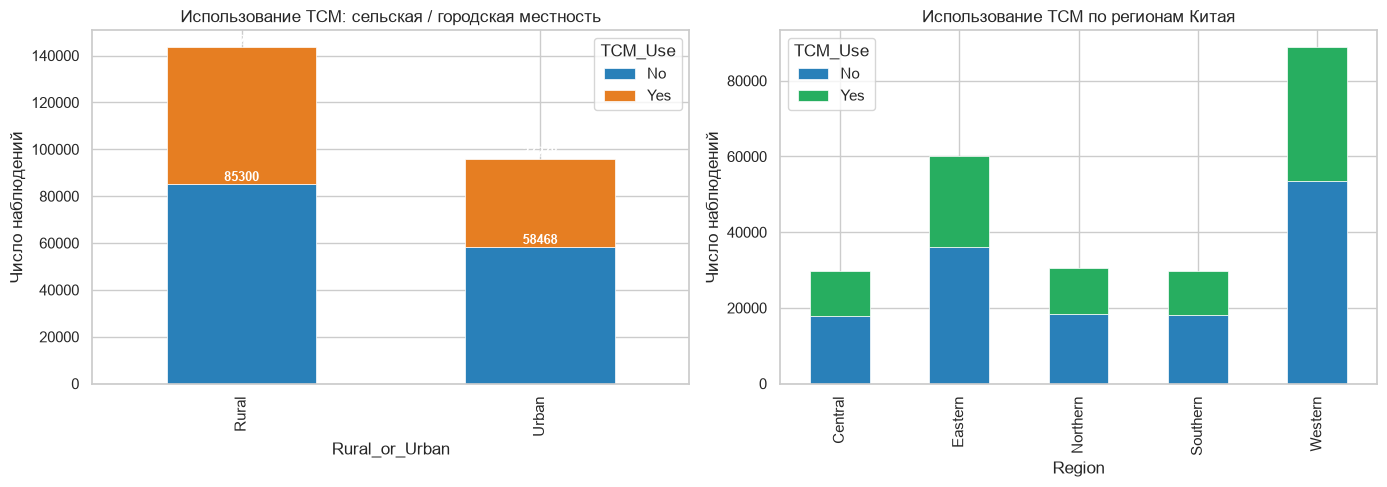

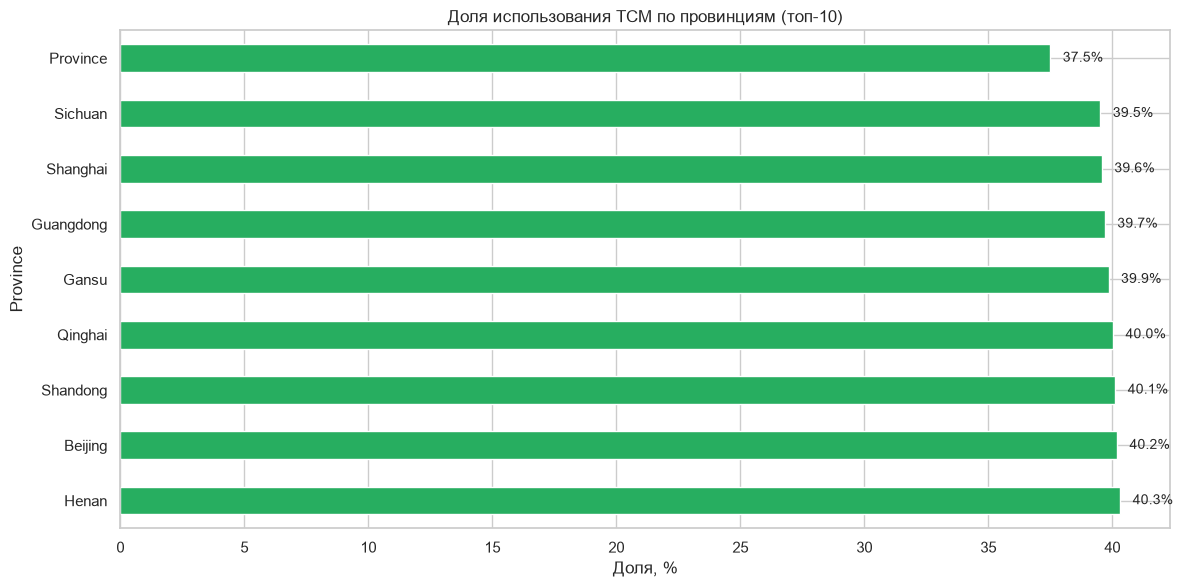

In [6]:
print("ГИПОТЕЗА Н1: Использование TCM")


chi2_a, p_a, cv_a, ct_a = chi2_cramers_v(df, 'Rural_or_Urban', 'TCM_Use', "Н1а: TCM_Use x Rural_or_Urban")
chi2_b, p_b, cv_b, ct_b = chi2_cramers_v(df, 'Region', 'TCM_Use', "Н1б: TCM_Use x Region")
chi2_c, p_c, cv_c, ct_c = chi2_cramers_v(df, 'Province', 'TCM_Use', "Н1в: TCM_Use x Province")

tcm_prov = df.groupby('Province')['TCM_Use_bin'].agg(['mean', 'count'])
tcm_prov['mean'] = (tcm_prov['mean'] * 100).round(2)
print(f"\nДоля использования TCM по провинциям (%):\n{tcm_prov}")

# Визуализация Н1
palette_binary = ['#2980b9', '#e67e22']
palette_region = ['#2980b9', '#27ae60', '#c0392b', '#8e44ad', '#f39c12']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ct_a.plot(kind='bar', stacked=True, ax=axes[0], color=palette_binary, edgecolor='white', linewidth=0.5)
axes[0].set_title('Использование TCM: сельская / городская местность', fontsize=12)
axes[0].set_ylabel('Число наблюдений')
axes[0].legend(title='TCM_Use')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', fontsize=9, color='white', fontweight='bold')

ct_b.plot(kind='bar', stacked=True, ax=axes[1], color=palette_region, edgecolor='white', linewidth=0.5)
axes[1].set_title('Использование TCM по регионам Китая', fontsize=12)
axes[1].set_ylabel('Число наблюдений')
axes[1].legend(title='TCM_Use')

plt.tight_layout()
plt.savefig('H1_TCM_usage.png', dpi=200, bbox_inches='tight')
plt.show()

fig2, ax2 = plt.subplots(figsize=(12, 6))
top_prov = tcm_prov.sort_values('mean', ascending=False).head(10)
top_prov['mean'].plot(kind='barh', ax=ax2, color='#27ae60', edgecolor='white')
ax2.set_title('Доля использования TCM по провинциям (топ-10)', fontsize=12)
ax2.set_xlabel('Доля, %')
for i, v in enumerate(top_prov['mean'].values):
    ax2.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=10)
plt.tight_layout()
plt.savefig('H1_TCM_by_province.png', dpi=200, bbox_inches='tight')
plt.show()

#H2

ГИПОТЕЗА Н2: Доступ к здравоохранению

Н2а: Income_Level x Healthcare_Access
Таблица сопряжённости:
Healthcare_Access   Good  Moderate   Poor
Income_Level                             
High               27680     27719  23836
Low                24931     27086  28236
Middle             25997     27337  26444
Хи-квадрат = 522.1680, df = 4, p-value = 0.000000
V Крамера = 0.0330
Вывод: связь статистически значима (p < 0.05)

Н2б: Region x Healthcare_Access
Таблица сопряжённости:
Healthcare_Access   Good  Moderate   Poor
Region                                   
Central             9658     10287   9927
Eastern            19945     20516  19603
Northern           10084     10589   9962
Southern            9784     10207   9866
Western            29137     30543  29158
Хи-квадрат = 9.7644, df = 8, p-value = 0.281955
V Крамера = 0.0045
Вывод: связь статистически не значима (p >= 0.05)

Н2г: Крускал-Уоллис (Province -> Healthcare_Access)
H = 11.1857, p = 0.191400


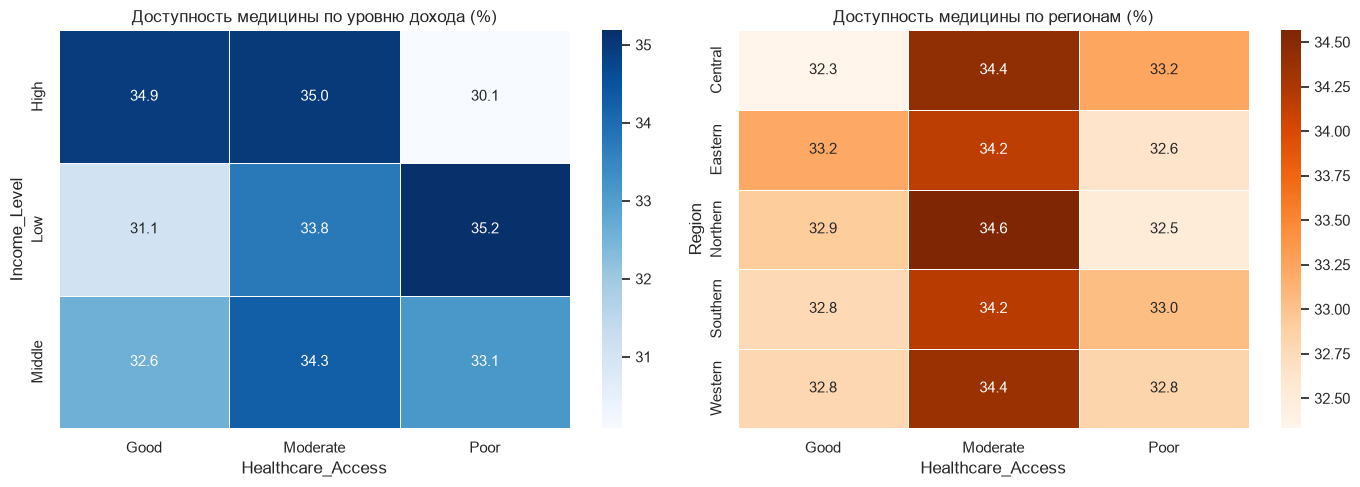

In [7]:
print("ГИПОТЕЗА Н2: Доступ к здравоохранению")

chi2_cramers_v(df, 'Income_Level', 'Healthcare_Access', "Н2а: Income_Level x Healthcare_Access")
chi2_cramers_v(df, 'Region', 'Healthcare_Access', "Н2б: Region x Healthcare_Access")

groups = [df[df['Province'] == p]['Healthcare_Access_num'].dropna() for p in df['Province'].unique()]
h_stat, p_kw = kruskal(*groups)
print(f"\nН2г: Крускал-Уоллис (Province -> Healthcare_Access)")
print(f"H = {h_stat:.4f}, p = {p_kw:.6f}")

# Визуализация Н2
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ct_inc = pd.crosstab(df['Income_Level'], df['Healthcare_Access'], normalize='index') * 100
sns.heatmap(ct_inc, annot=True, fmt='.1f', cmap='Blues', ax=axes[0], linewidths=0.5)
axes[0].set_title('Доступность медицины по уровню дохода (%)')

ct_reg = pd.crosstab(df['Region'], df['Healthcare_Access'], normalize='index') * 100
sns.heatmap(ct_reg, annot=True, fmt='.1f', cmap='Oranges', ax=axes[1], linewidths=0.5)
axes[1].set_title('Доступность медицины по регионам (%)')

plt.tight_layout()
plt.savefig('H2_healthcare_access.png', dpi=200, bbox_inches='tight')
plt.show()

#H3

ГИПОТЕЗА Н3: Предикторы качества питания (Diet_Score)

Крускал-Уоллис: Регион -> Diet_Score
H = 3.1606, p = 0.531315
Вывод: влияние Регион не значимо

Крускал-Уоллис: Доход -> Diet_Score
H = 181.9379, p = 0.000000
Вывод: Доход значимо влияет на качество питания

Крускал-Уоллис: Образование -> Diet_Score
H = 218.9011, p = 0.000000
Вывод: Образование значимо влияет на качество питания

Множественная регрессия: Diet_Score ~ Region + Income + Education
R² = 0.0015
Коэффициенты модели:
  Region_Eastern: 0.0033
  Region_Northern: 0.0086
  Region_Southern: 0.0096
  Region_Western: 0.0029
  Income_Level_Low: -0.0417
  Income_Level_Middle: -0.0400
  Education_Level_None: -0.0400
  Education_Level_Primary: -0.0426
  Education_Level_Secondary: 0.0041


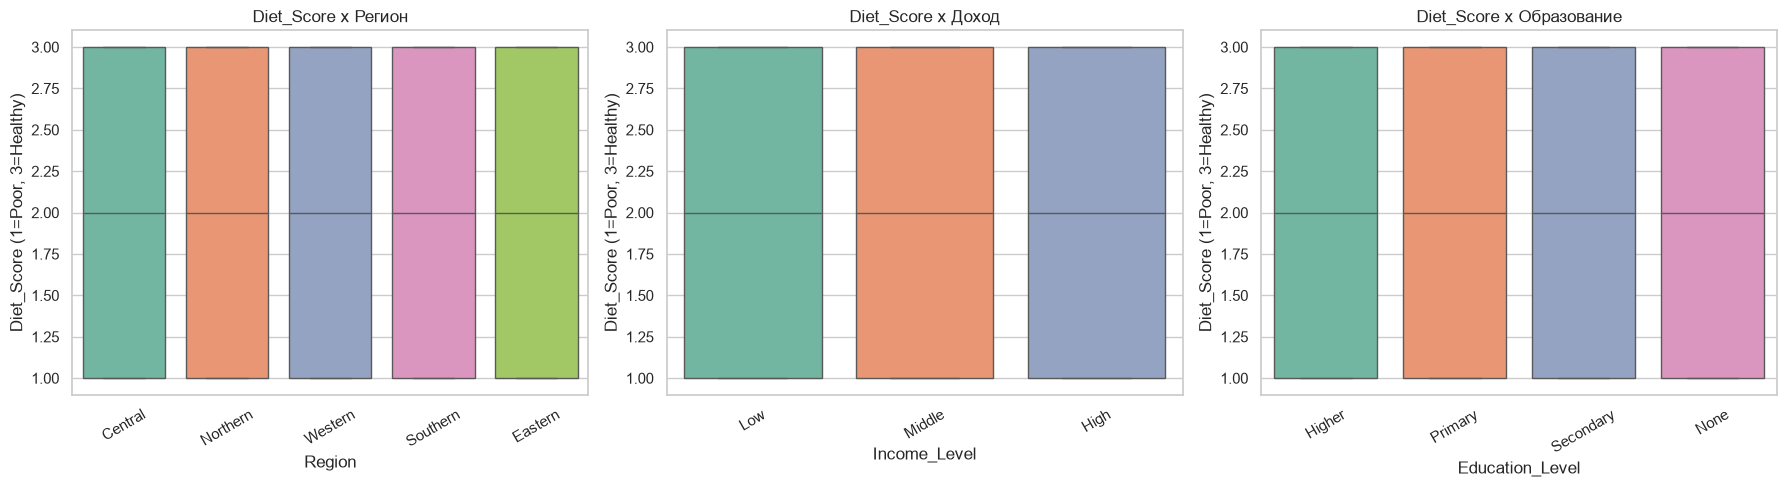

In [8]:
print("ГИПОТЕЗА Н3: Предикторы качества питания (Diet_Score)")

predictors = [('Region', 'Регион'), ('Income_Level', 'Доход'), ('Education_Level', 'Образование')]

for col_name, col_label in predictors:
    groups = [df[df[col_name] == g]['Diet_Score_num'].dropna() for g in df[col_name].unique()]
    h, p = kruskal(*groups)
    print(f"\nКрускал-Уоллис: {col_label} -> Diet_Score")
    print(f"H = {h:.4f}, p = {p:.6f}")
    if p < 0.05:
        print(f"Вывод: {col_label} значимо влияет на качество питания")
    else:
        print(f"Вывод: влияние {col_label} не значимо")

features_h3 = pd.get_dummies(df[['Region', 'Income_Level', 'Education_Level']], drop_first=True)
X_h3 = features_h3.values
y_h3 = df['Diet_Score_num'].values

model_h3 = LinearRegression().fit(X_h3, y_h3)
r2 = model_h3.score(X_h3, y_h3)
print(f"\nМножественная регрессия: Diet_Score ~ Region + Income + Education")
print(f"R² = {r2:.4f}")
print("Коэффициенты модели:")
for name, coef in zip(features_h3.columns, model_h3.coef_):
    print(f"  {name}: {coef:.4f}")

# Визуализация Н3
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
palette_h3 = sns.color_palette('Set2')

for i, (col, title) in enumerate(predictors):
    sns.boxplot(x=col, y='Diet_Score_num', data=df, ax=axes[i], palette=palette_h3)
    axes[i].set_title(f'Diet_Score x {title}')
    axes[i].set_ylabel('Diet_Score (1=Poor, 3=Healthy)')
    axes[i].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('H3_diet_score.png', dpi=200, bbox_inches='tight')
plt.show()

#H4

ГИПОТЕЗА Н4: Гипертония и инфаркт

Таблица сопряжённости:
Heart_Attack      No   Yes
Hypertension              
No            164397  6010
Yes            63275  5584

Доля инфарктов у пациентов с гипертонией: 8.11%
Доля инфарктов у пациентов без гипертонии: 3.53%

Относительный риск (RR) = 2.30
-> У пациентов с гипертонией инфаркт возникает в 2.30 раз(а) чаще

Отношение шансов (OR) = 2.41
Хи-квадрат = 2232.5081, p-value = 0.000000


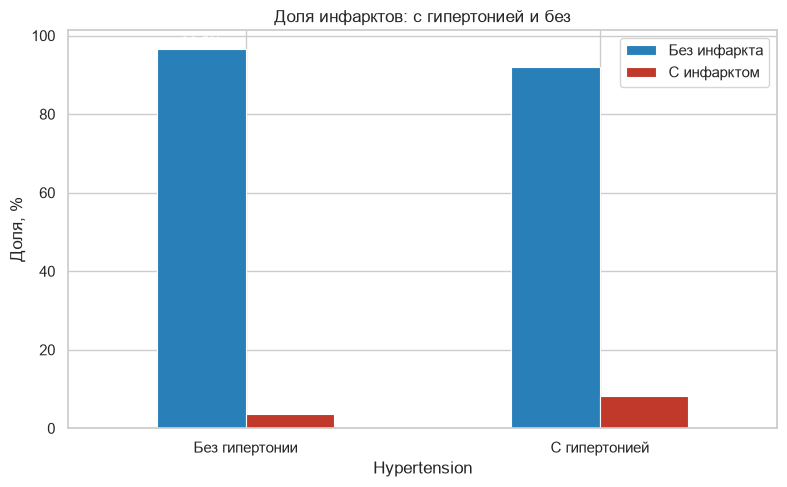

In [9]:
print("ГИПОТЕЗА Н4: Гипертония и инфаркт")

ct_h4 = pd.crosstab(df['Hypertension'], df['Heart_Attack'])
print(f"\nТаблица сопряжённости:\n{ct_h4}")

risk_hyp = ct_h4.loc['Yes', 'Yes'] / ct_h4.loc['Yes'].sum()
risk_nohyp = ct_h4.loc['No', 'Yes'] / ct_h4.loc['No'].sum()
rr = risk_hyp / risk_nohyp

odds_hyp = ct_h4.loc['Yes', 'Yes'] / ct_h4.loc['Yes', 'No']
odds_nohyp = ct_h4.loc['No', 'Yes'] / ct_h4.loc['No', 'No']
or_val = odds_hyp / odds_nohyp

chi2, p, dof, _ = chi2_contingency(ct_h4)

print(f"\nДоля инфарктов у пациентов с гипертонией: {risk_hyp*100:.2f}%")
print(f"Доля инфарктов у пациентов без гипертонии: {risk_nohyp*100:.2f}%")
print(f"\nОтносительный риск (RR) = {rr:.2f}")
print(f"-> У пациентов с гипертонией инфаркт возникает в {rr:.2f} раз(а) чаще")
print(f"\nОтношение шансов (OR) = {or_val:.2f}")
print(f"Хи-квадрат = {chi2:.4f}, p-value = {p:.6f}")

# Визуализация Н4
fig, ax = plt.subplots(figsize=(8, 5))
ct_h4_norm = ct_h4.div(ct_h4.sum(axis=1), axis=0) * 100
ct_h4_norm.plot(kind='bar', ax=ax, color=['#2980b9', '#c0392b'], edgecolor='white', linewidth=0.8)
ax.set_title('Доля инфарктов: с гипертонией и без')
ax.set_ylabel('Доля, %')
ax.set_xticklabels(['Без гипертонии', 'С гипертонией'], rotation=0)
ax.legend(['Без инфаркта', 'С инфарктом'])

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', fontsize=10, color='white', fontweight='bold')

plt.tight_layout()
plt.savefig('H4_hypertension.png', dpi=200, bbox_inches='tight')
plt.show()

#H5

ГИПОТЕЗА Н5: Накопительный эффект факторов риска

Распределение числа негативных факторов:
Neg_Factor_Count
0      4963
1     24196
2     51948
3     64355
4     51144
5     27876
6     10984
7      3070
8       639
9        85
10        6
Name: count, dtype: int64

Логистическая регрессия: Heart_Attack ~ Neg_Factor_Count
Коэффициент = 0.2095
OR на каждый дополнительный фактор = 1.2331
-> Каждый дополнительный негативный фактор увеличивает шансы инфаркта в 1.23 раз(а)

Важность факторов (Random Forest):
  1. Previous_Heart_Attack_bin: 0.1729 <-- ТОП-3
  2. Hypertension_bin: 0.1446 <-- ТОП-3
  3. Alcohol_Consumption_bin: 0.0789 <-- ТОП-3
  4. High_Stress_bin: 0.0765
  5. High_Pollution_bin: 0.0738
  6. Family_History_CVD_bin: 0.0717
  7. Low_Activity_bin: 0.0712
  8. High_Cholesterol_bin: 0.0579
  9. Smoking_Status_bin: 0.0566
  10. Poor_Diet_bin: 0.0549
  11. Chronic_Kidney_Disease_bin: 0.0490
  12. Diabetes_bin: 0.0466
  13. Obesity_bin: 0.0453


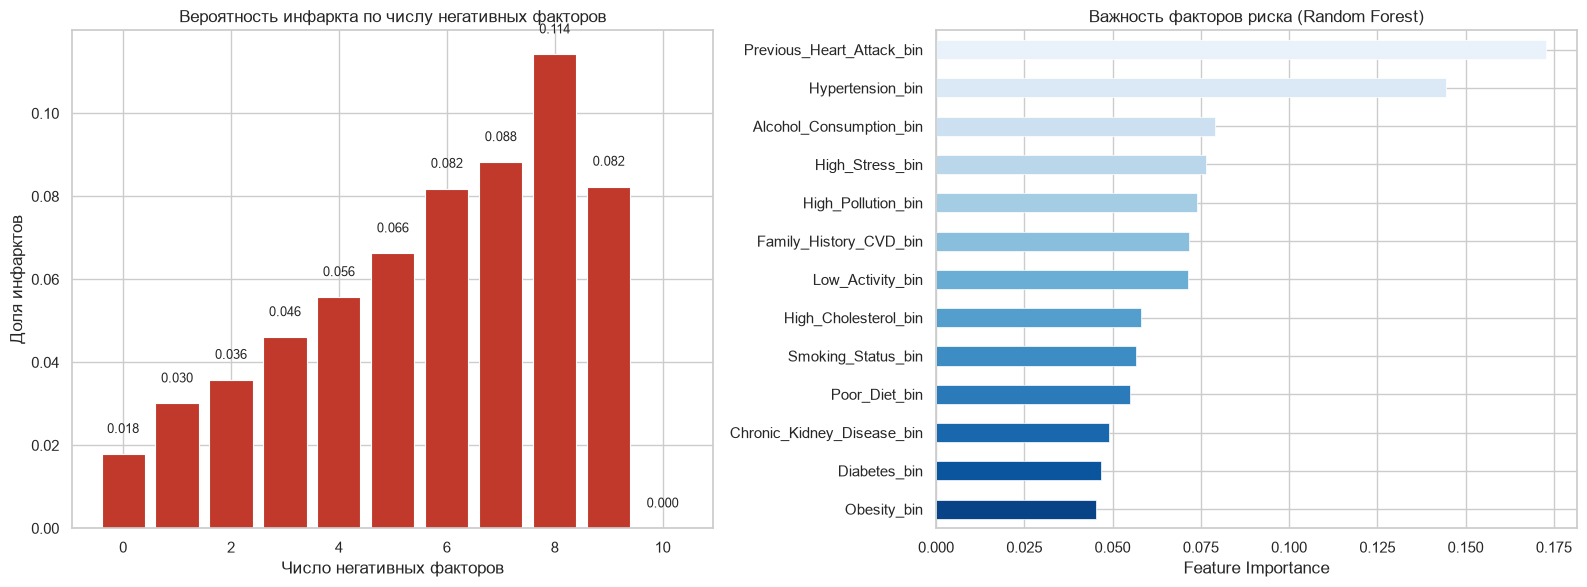

In [10]:
print("ГИПОТЕЗА Н5: Накопительный эффект факторов риска")

df['Poor_Diet_bin'] = (df['Diet_Score'] == 'Poor').astype(int)
df['Low_Activity_bin'] = (df['Physical_Activity'] == 'Low').astype(int)
df['High_Stress_bin'] = (df['Stress_Level'] == 'High').astype(int)
df['High_Cholesterol_bin'] = (df['Cholesterol_Level'] == 'High').astype(int)
df['High_Pollution_bin'] = (df['Air_Pollution_Exposure'] == 'High').astype(int)

negative_factors = [
    'Smoking_Status_bin', 'Hypertension_bin', 'Alcohol_Consumption_bin',
    'Family_History_CVD_bin', 'Previous_Heart_Attack_bin',
    'Diabetes_bin', 'Obesity_bin', 'Chronic_Kidney_Disease_bin',
    'Poor_Diet_bin', 'Low_Activity_bin', 'High_Stress_bin',
    'High_Cholesterol_bin', 'High_Pollution_bin'
]

df['Neg_Factor_Count'] = df[negative_factors].sum(axis=1)
print(f"\nРаспределение числа негативных факторов:\n{df['Neg_Factor_Count'].value_counts().sort_index()}")

X_n5 = df[['Neg_Factor_Count']].values
y_n5 = df['Heart_Attack_bin'].values

lr_n5 = LogisticRegression().fit(X_n5, y_n5)
coef = lr_n5.coef_[0][0]
or_per_factor = np.exp(coef)

print(f"\nЛогистическая регрессия: Heart_Attack ~ Neg_Factor_Count")
print(f"Коэффициент = {coef:.4f}")
print(f"OR на каждый дополнительный фактор = {or_per_factor:.4f}")
print(f"-> Каждый дополнительный негативный фактор увеличивает шансы инфаркта в {or_per_factor:.2f} раз(а)")

X_n5b = df[negative_factors].values
y_n5b = df['Heart_Attack_bin'].values

rf = RandomForestClassifier(n_estimators=200, random_state=42).fit(X_n5b, y_n5b)
importances = pd.Series(rf.feature_importances_, index=negative_factors).sort_values(ascending=False)

print(f"\nВажность факторов (Random Forest):")
for i, (feat, imp) in enumerate(importances.items()):
    marker = " <-- ТОП-3" if i < 3 else ""
    print(f"  {i+1}. {feat}: {imp:.4f}{marker}")

# Визуализация Н5
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

mean_risk = df.groupby('Neg_Factor_Count')['Heart_Attack_bin'].mean()
axes[0].bar(mean_risk.index, mean_risk.values, color='#c0392b', edgecolor='white', linewidth=0.8)
axes[0].set_title('Вероятность инфаркта по числу негативных факторов')
axes[0].set_xlabel('Число негативных факторов')
axes[0].set_ylabel('Доля инфарктов')
for i, v in enumerate(mean_risk.values):
    axes[0].text(i, v + 0.005, f'{v:.3f}', ha='center', fontsize=9)

palette_rf = sns.color_palette('Blues', len(importances))
importances.plot(kind='barh', ax=axes[1], color=palette_rf, edgecolor='white', linewidth=0.5)
axes[1].set_title('Важность факторов риска (Random Forest)')
axes[1].set_xlabel('Feature Importance')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig('H5_cumulative_factors.png', dpi=200, bbox_inches='tight')
plt.show()

#H6

ГИПОТЕЗА Н6: Взаимосвязи переменных образа жизни

Корреляционная матрица (Спирмен):
                     Stress_Level  Smoking_Status  Alcohol_Consumption  \
Stress_Level               1.0000         -0.0014              -0.0012   
Smoking_Status            -0.0014          1.0000               0.0001   
Alcohol_Consumption       -0.0012          0.0001               1.0000   
Physical_Activity          0.0002          0.0010              -0.0020   

                     Physical_Activity  
Stress_Level                    0.0002  
Smoking_Status                  0.0010  
Alcohol_Consumption            -0.0020  
Physical_Activity               1.0000  

Попарные тесты хи-квадрат:
  Stress_Level x Smoking_Status: chi2=0.65, p=0.721481, V=0.0017 (не значимо)
  Stress_Level x Alcohol_Consumption: chi2=0.43, p=0.807165, V=0.0013 (не значимо)
  Stress_Level x Physical_Activity: chi2=0.58, p=0.965690, V=0.0011 (не значимо)
  Smoking_Status x Alcohol_Consumption: chi2=0.00, p=0.949407, V=0.000

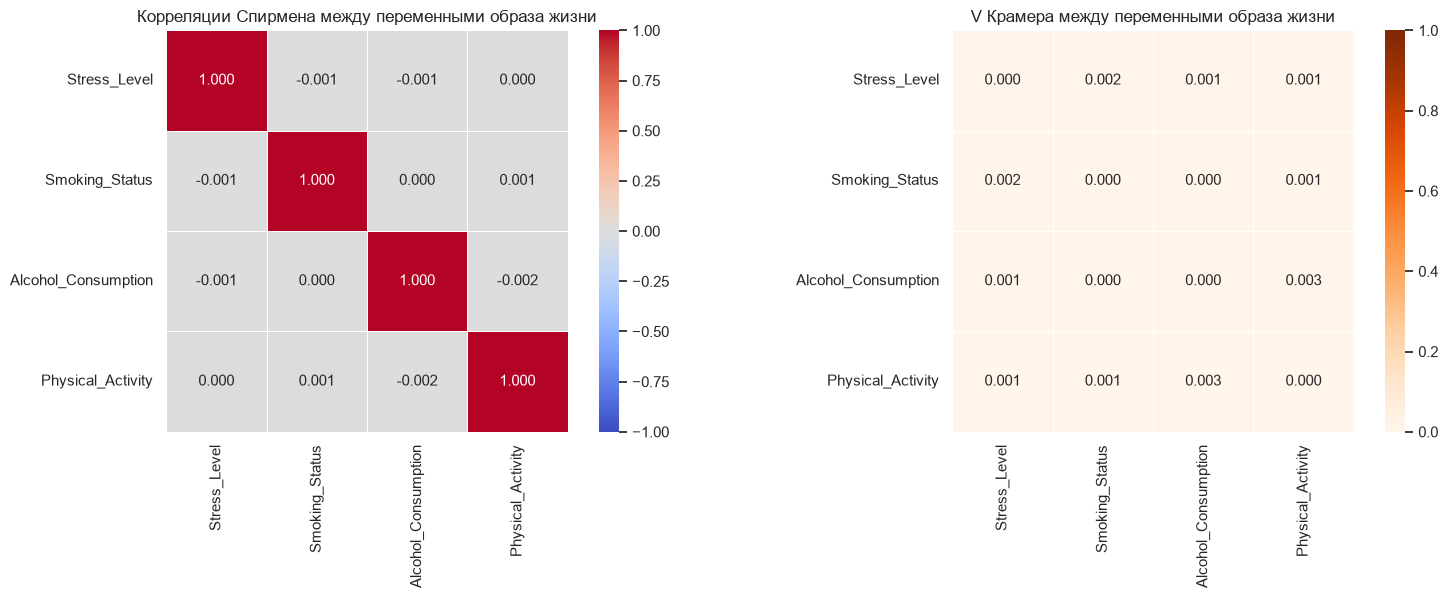

In [11]:
print("ГИПОТЕЗА Н6: Взаимосвязи переменных образа жизни")

vars_n6 = ['Stress_Level', 'Smoking_Status', 'Alcohol_Consumption', 'Physical_Activity']
vars_n6_num = ['Stress_Level_num', 'Smoking_Status_bin', 'Alcohol_Consumption_bin', 'Physical_Activity_num']

corr_matrix = df[vars_n6_num].corr(method='spearman')
corr_matrix.index = vars_n6
corr_matrix.columns = vars_n6
print(f"\nКорреляционная матрица (Спирмен):\n{corr_matrix.round(4)}")

print(f"\nПопарные тесты хи-квадрат:")
pairs = [(vars_n6[i], vars_n6[j]) for i in range(len(vars_n6)) for j in range(i+1, len(vars_n6))]

cramers_matrix = pd.DataFrame(np.zeros((4, 4)), index=vars_n6, columns=vars_n6)

for v1, v2 in pairs:
    ct = pd.crosstab(df[v1], df[v2])
    chi2, p, dof, _ = chi2_contingency(ct)
    n = ct.sum().sum()
    cv = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    cramers_matrix.loc[v1, v2] = cv
    cramers_matrix.loc[v2, v1] = cv
    sig = "значимо" if p < 0.05 else "не значимо"
    print(f"  {v1} x {v2}: chi2={chi2:.2f}, p={p:.6f}, V={cv:.4f} ({sig})")

# Визуализация Н6
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', center=0,
            ax=axes[0], square=True, vmin=-1, vmax=1, linewidths=0.5)
axes[0].set_title('Корреляции Спирмена между переменными образа жизни')

sns.heatmap(cramers_matrix, annot=True, fmt='.3f', cmap='Oranges',
            ax=axes[1], square=True, vmin=0, vmax=1, linewidths=0.5)
axes[1].set_title('V Крамера между переменными образа жизни')

plt.tight_layout()
plt.savefig('H6_lifestyle_correlations.png', dpi=200, bbox_inches='tight')
plt.show()

#H7

ГИПОТЕЗА Н7: Паттерны образа жизни пенсионеров

Количество пенсионеров: 108992 (45.6% от выборки)

Возраст:
  Средний: 72.8 +/- 10.7 лет
  Медиана: 73 лет
  Мин/Макс: 27 / 90

Распределение по полу:
Gender
Female    50.3
Male      49.7
Name: proportion, dtype: float64

Характеристики пенсионеров (доли, %):
  Smoking_Status: {'Smoker': 50.1, 'Non-Smoker': 49.9}
  Alcohol_Consumption: {'No': 70.2, 'Yes': 29.8}
  Physical_Activity: {'Medium': 33.4, 'High': 33.3, 'Low': 33.3}
  Diet_Score: {'Healthy': 35.1, 'Moderate': 34.0, 'Poor': 30.9}
  Stress_Level: {'Low': 33.7, 'High': 33.2, 'Medium': 33.2}
  Hypertension: {'No': 56.1, 'Yes': 43.9}
  Diabetes: {'No': 88.6, 'Yes': 11.4}
  TCM_Use: {'No': 60.2, 'Yes': 39.8}
  Rural_or_Urban: {'Rural': 60.1, 'Urban': 39.9}
  Heart_Attack: {'No': 93.7, 'Yes': 6.3}

Сравнение групп занятости (средние значения):
                       Pensioners  Employed  Unemployed
Age                        72.822    45.506      59.665
Income_Level_num            1.997

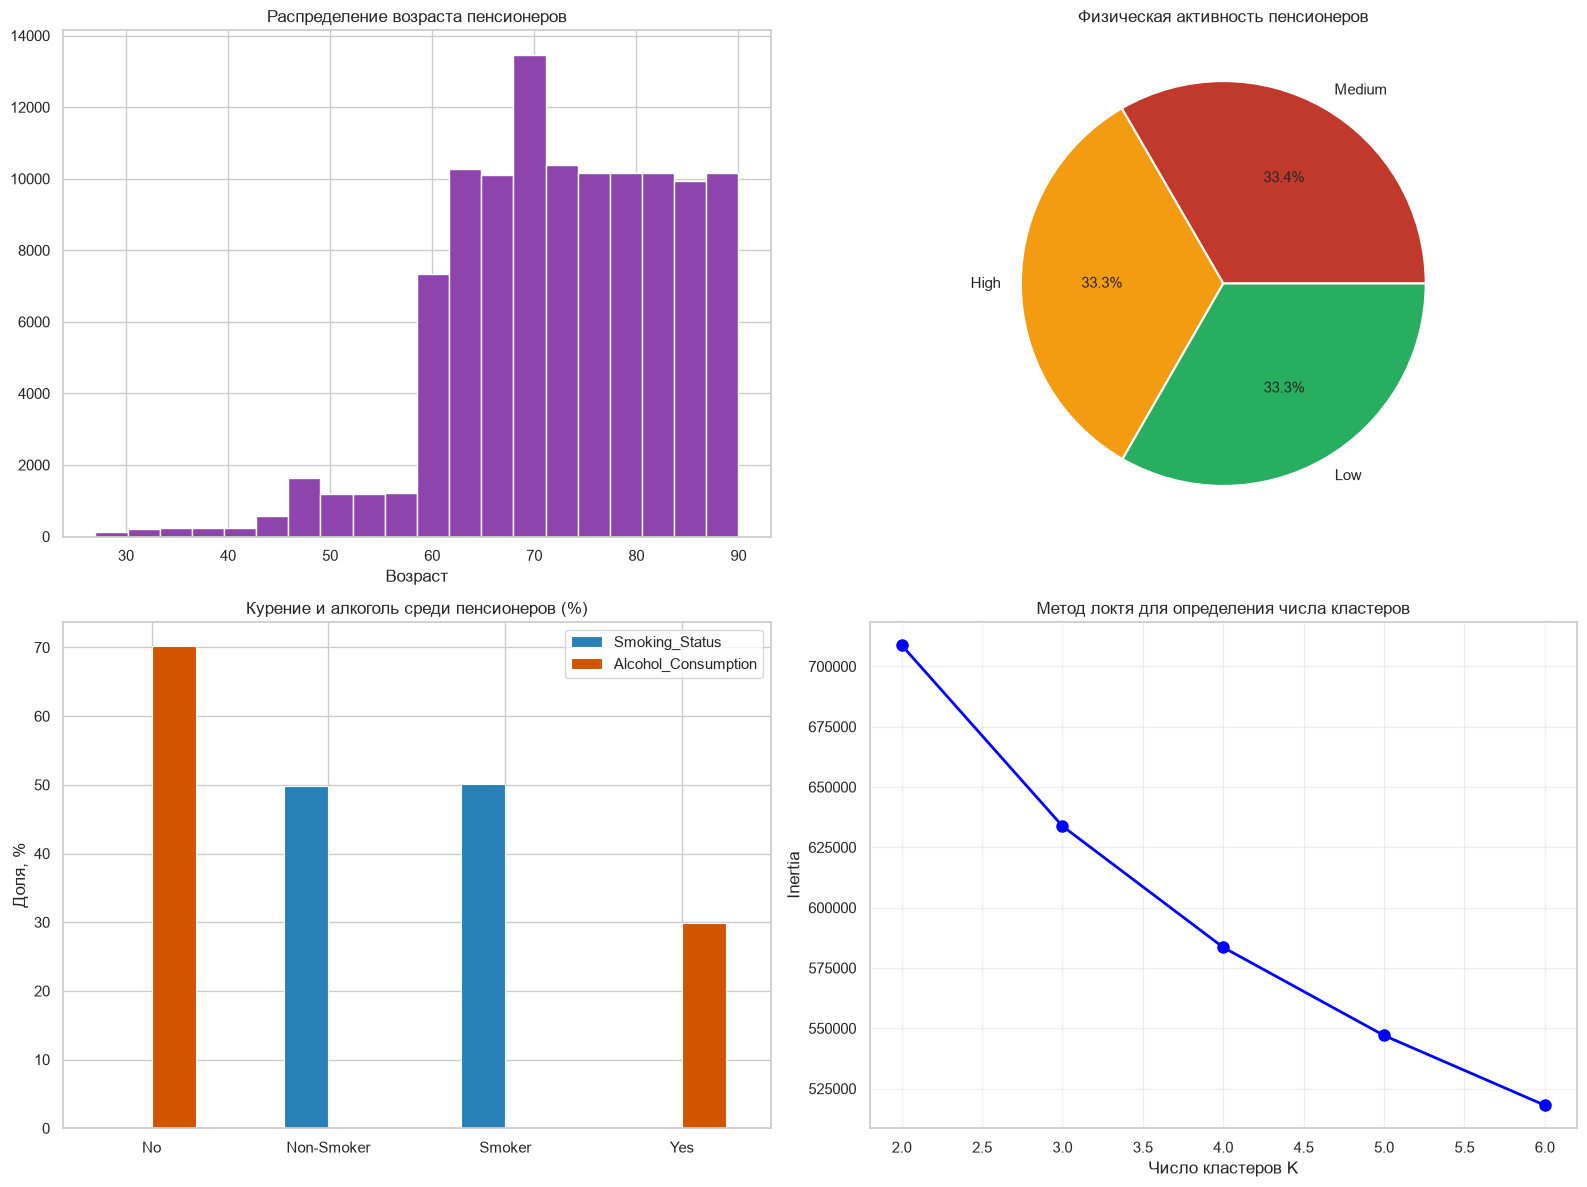

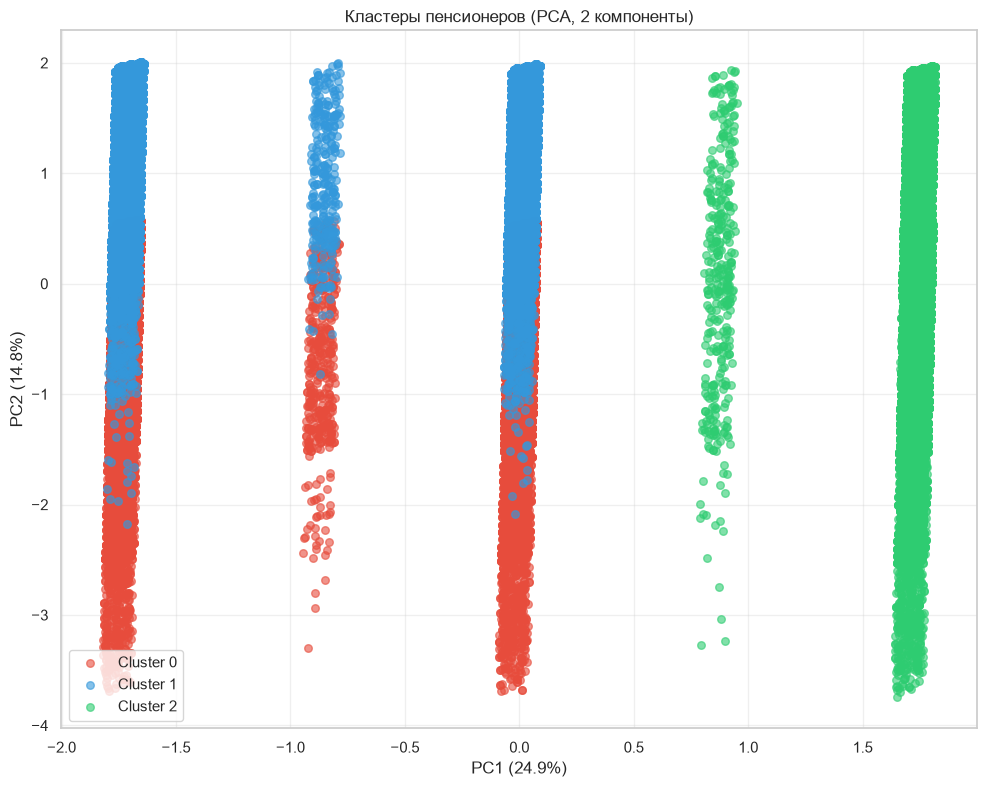

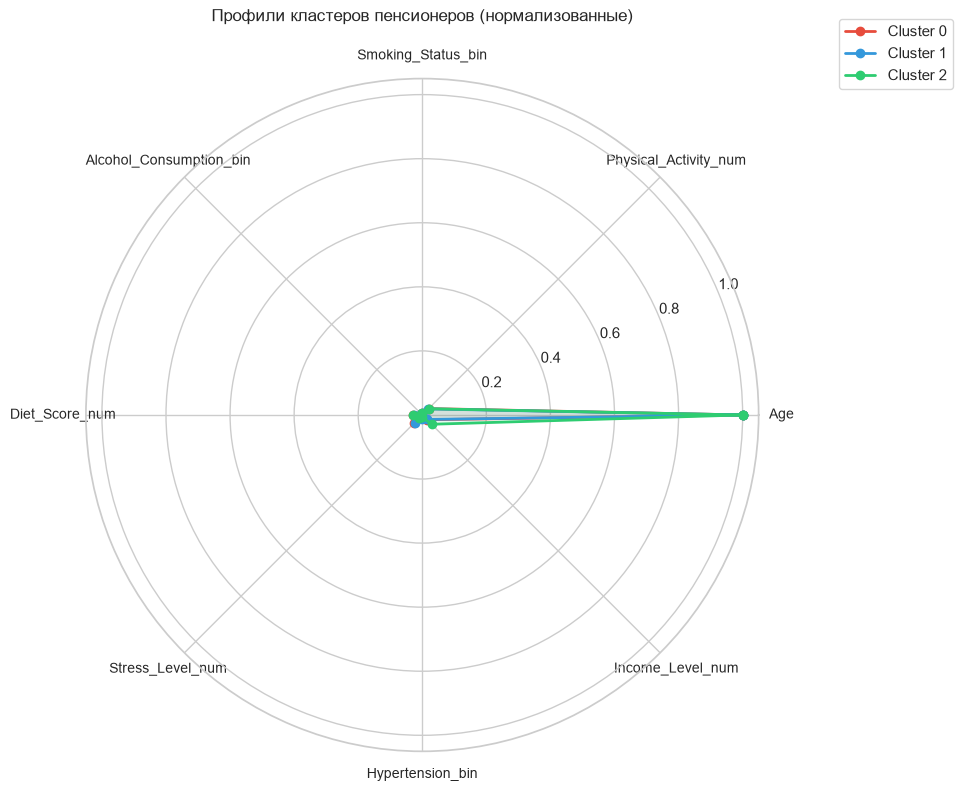

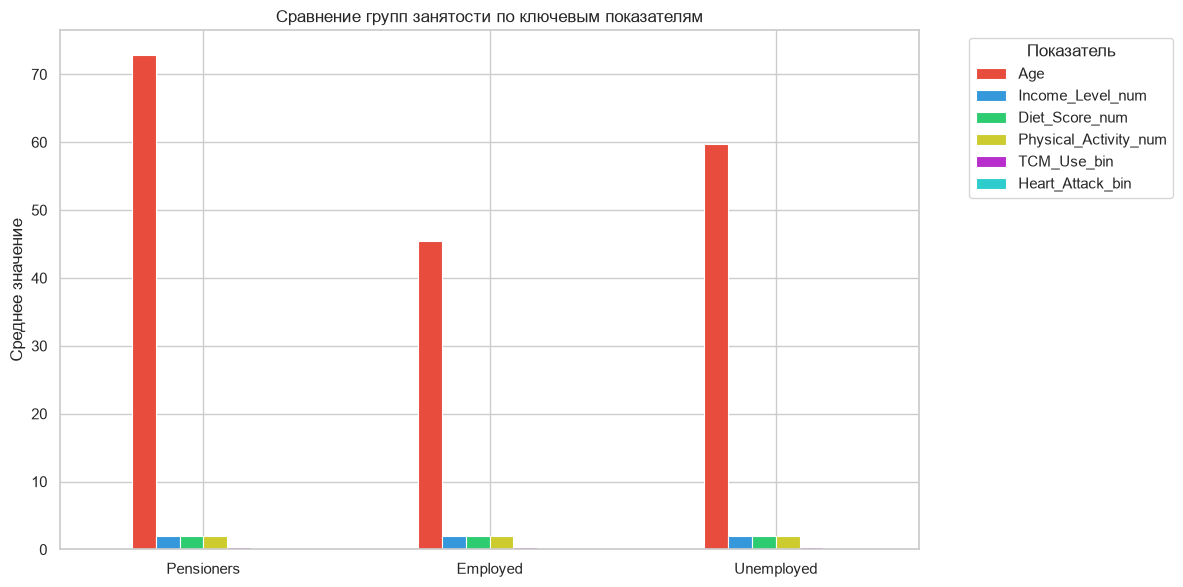


Итоговый вывод по Н7:
Пенсионеры составляют 45.6% выборки.
Средний возраст пенсионеров: 72.8 лет.
Наиболее распространённый фактор риска: Smoking_Status_bin (50.1%).
Фактор с наибольшей корреляцией с инфарктом: Previous_Heart_Attack_bin (r=0.0876).
Выявлено 3 кластера пенсионеров.


In [12]:
print("ГИПОТЕЗА Н7: Паттерны образа жизни пенсионеров")

retired = df[df['Employment_Status'] == 'Retired'].copy()
print(f"\nКоличество пенсионеров: {len(retired)} ({len(retired)/len(df)*100:.1f}% от выборки)")

print(f"\nВозраст:")
print(f"  Средний: {retired['Age'].mean():.1f} +/- {retired['Age'].std():.1f} лет")
print(f"  Медиана: {retired['Age'].median():.0f} лет")
print(f"  Мин/Макс: {retired['Age'].min():.0f} / {retired['Age'].max():.0f}")

print(f"\nРаспределение по полу:\n{retired['Gender'].value_counts(normalize=True).mul(100).round(1)}")

desc_cols = ['Smoking_Status', 'Alcohol_Consumption', 'Physical_Activity',
             'Diet_Score', 'Stress_Level', 'Hypertension', 'Diabetes',
             'TCM_Use', 'Rural_or_Urban', 'Heart_Attack']

print(f"\nХарактеристики пенсионеров (доли, %):")
for col in desc_cols:
    dist = retired[col].value_counts(normalize=True).mul(100).round(1)
    print(f"  {col}: {dist.to_dict()}")

# Сравнение групп занятости
compare_cols = ['Age', 'Income_Level_num', 'Diet_Score_num',
                'Physical_Activity_num', 'Stress_Level_num',
                'TCM_Use_bin', 'Heart_Attack_bin', 'Hypertension_bin']

comparison = pd.DataFrame(index=compare_cols)
for status, label in [('Retired', 'Pensioners'), ('Employed', 'Employed'), ('Unemployed', 'Unemployed')]:
    subset = df[df['Employment_Status'] == status]
    comparison[label] = subset[compare_cols].mean().round(3)

print(f"\nСравнение групп занятости (средние значения):\n{comparison}")

# Факторы риска среди пенсионеров
risk_factors_ret = ['Hypertension_bin', 'Diabetes_bin', 'Obesity_bin',
                    'Smoking_Status_bin', 'Alcohol_Consumption_bin',
                    'High_Cholesterol_bin', 'Poor_Diet_bin',
                    'Low_Activity_bin', 'High_Stress_bin',
                    'Family_History_CVD_bin', 'Previous_Heart_Attack_bin']

risk_ret = retired[risk_factors_ret].mean().sort_values(ascending=False)
print("\nРаспространённость факторов риска среди пенсионеров (%):")
for feat, val in risk_ret.items():
    print(f"  {feat}: {val*100:.1f}%")

corr_with_ha = retired[risk_factors_ret].apply(
    lambda x: x.corr(retired['Heart_Attack_bin'])).sort_values(ascending=False)
print(f"\nКорреляция факторов риска с инфарктом (пенсионеры):")
for feat, val in corr_with_ha.items():
    print(f"  {feat}: r={val:.4f}")

# Кластеризация пенсионеров
cluster_features = ['Age', 'Physical_Activity_num', 'Smoking_Status_bin',
                    'Alcohol_Consumption_bin', 'Diet_Score_num', 'Stress_Level_num',
                    'Hypertension_bin', 'Income_Level_num']

X_ret = retired[cluster_features].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_ret)

inertias = []
K_range = range(2, 7)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled)
    inertias.append(km.inertia_)

km_final = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
X_ret_clustered = X_ret.copy()
X_ret_clustered['Cluster'] = km_final.labels_

print("\nПрофили кластеров (средние значения признаков):")
cluster_profiles = X_ret_clustered.groupby('Cluster')[cluster_features].mean()
print(cluster_profiles.round(3))

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
X_ret_clustered['PC1'] = X_pca[:, 0]
X_ret_clustered['PC2'] = X_pca[:, 1]

# Визуализация Н7
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes[0, 0].hist(retired['Age'], bins=20, color='#8e44ad', edgecolor='white')
axes[0, 0].set_title('Распределение возраста пенсионеров')
axes[0, 0].set_xlabel('Возраст')

palette_activity = ['#c0392b', '#f39c12', '#27ae60']
retired['Physical_Activity'].value_counts().plot(
    kind='pie', autopct='%1.1f%%', ax=axes[0, 1], colors=palette_activity,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[0, 1].set_title('Физическая активность пенсионеров')
axes[0, 1].set_ylabel('')

lifestyle_ret = retired[['Smoking_Status', 'Alcohol_Consumption']].apply(
    lambda x: x.value_counts(normalize=True) * 100)
lifestyle_ret.plot(kind='bar', ax=axes[1, 0], color=['#2980b9', '#d35400'], edgecolor='white', linewidth=0.8)
axes[1, 0].set_title('Курение и алкоголь среди пенсионеров (%)')
axes[1, 0].set_ylabel('Доля, %')
axes[1, 0].tick_params(axis='x', rotation=0)

axes[1, 1].plot(list(K_range), inertias, 'bo-', linewidth=2, markersize=8)
axes[1, 1].set_title('Метод локтя для определения числа кластеров')
axes[1, 1].set_xlabel('Число кластеров K')
axes[1, 1].set_ylabel('Inertia')
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('H7_retired_descriptive.png', dpi=200, bbox_inches='tight')
plt.show()

# PCA кластеров
fig, ax = plt.subplots(figsize=(10, 8))
palette_clusters = ['#e74c3c', '#3498db', '#2ecc71']

for cluster_id in sorted(X_ret_clustered['Cluster'].unique()):
    mask = X_ret_clustered['Cluster'] == cluster_id
    ax.scatter(X_ret_clustered.loc[mask, 'PC1'], X_ret_clustered.loc[mask, 'PC2'],
               label=f'Cluster {cluster_id}', alpha=0.6, s=30, color=palette_clusters[cluster_id])

ax.set_title('Кластеры пенсионеров (PCA, 2 компоненты)')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('H7_clusters_pca.png', dpi=200, bbox_inches='tight')
plt.show()

# Радарные диаграммы
radar_features = cluster_features
angles = np.linspace(0, 2 * np.pi, len(radar_features), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))

for cluster_id in sorted(X_ret_clustered['Cluster'].unique()):
    profile = X_ret_clustered[X_ret_clustered['Cluster'] == cluster_id][radar_features].mean().values
    profile = np.concatenate([profile, [profile[0]]])
    profile_norm = profile / profile.max() if profile.max() > 0 else profile
    ax.plot(angles, profile_norm, 'o-', linewidth=2, label=f'Cluster {cluster_id}', color=palette_clusters[cluster_id])
    ax.fill(angles, profile_norm, alpha=0.1, color=palette_clusters[cluster_id])

ax.set_xticks(angles[:-1])
ax.set_xticklabels(radar_features, fontsize=10)
ax.set_title('Профили кластеров пенсионеров (нормализованные)', fontsize=12, pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.savefig('H7_cluster_profiles_radar.png', dpi=200, bbox_inches='tight')
plt.show()

# Сравнение групп занятости
fig, ax = plt.subplots(figsize=(12, 6))
compare_plot = comparison.loc[['Age', 'Income_Level_num', 'Diet_Score_num',
                               'Physical_Activity_num', 'TCM_Use_bin', 'Heart_Attack_bin']].T
compare_plot.plot(kind='bar', ax=ax, color=['#e74c3c', '#3498db', '#2ecc71', "#cccc2e", "#b72ecc", "#2ecccc","#cc7d2e" ], edgecolor='white', linewidth=0.8)
ax.set_title('Сравнение групп занятости по ключевым показателям')
ax.set_ylabel('Среднее значение')
ax.legend(title='Показатель', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig('H7_employment_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

print("\nИтоговый вывод по Н7:")
print(f"Пенсионеры составляют {len(retired)/len(df)*100:.1f}% выборки.")
print(f"Средний возраст пенсионеров: {retired['Age'].mean():.1f} лет.")
print(f"Наиболее распространённый фактор риска: {risk_ret.index[0]} ({risk_ret.iloc[0]*100:.1f}%).")
print(f"Фактор с наибольшей корреляцией с инфарктом: {corr_with_ha.index[0]} (r={corr_with_ha.iloc[0]:.4f}).")
print(f"Выявлено {X_ret_clustered['Cluster'].nunique()} кластера пенсионеров.")